# 4.1 - code from module-3

In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression

In [3]:
df = pd.read_csv('data-week-3.csv')

df.columns = df.columns.str.lower().str.replace(' ', '_')

categorical_columns = list(df.dtypes[df.dtypes == 'object'].index)

for c in categorical_columns:
    df[c] = df[c].str.lower().str.replace(' ', '_')

df.totalcharges = pd.to_numeric(df.totalcharges, errors='coerce')
df.totalcharges = df.totalcharges.fillna(0)

df.churn = (df.churn == 'yes').astype(int)

In [4]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train.churn.values
y_val = df_val.churn.values
y_test = df_test.churn.values

del df_train['churn']
del df_val['churn']
del df_test['churn']

In [5]:
numerical = ['tenure', 'monthlycharges', 'totalcharges']

categorical = [
    'gender',
    'seniorcitizen',
    'partner',
    'dependents',
    'phoneservice',
    'multiplelines',
    'internetservice',
    'onlinesecurity',
    'onlinebackup',
    'deviceprotection',
    'techsupport',
    'streamingtv',
    'streamingmovies',
    'contract',
    'paperlessbilling',
    'paymentmethod',
]

dv = DictVectorizer(sparse=False)

train_dict = df_train[categorical + numerical].to_dict(orient='records')
X_train = dv.fit_transform(train_dict)

model = LogisticRegression()
model.fit(X_train, y_train)

val_dict = df_val[categorical + numerical].to_dict(orient='records')
X_val = dv.transform(val_dict)

y_pred = model.predict_proba(X_val)[:, 1]
churn_decision = (y_pred >= 0.5)
(y_val == churn_decision).mean()

/home/jihad/miniconda3/envs/ml_env/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


np.float64(0.8034066713981547)

# 4.2 - accuracy and dummy model

### finding best threshold

In [6]:
len(y_val)

1409

In [7]:
# amader validation set e total 1409 jon customer ase.

# churn_decision holo amader model er prediction. y_pred e threshold apply kore churn decision paisi.

(y_val == churn_decision).sum()

np.int64(1132)

In [8]:
# 1409 joner moddhe 1132 joner prediction ei correct korse. so accuracy holo: 

(y_val == churn_decision).mean()

np.float64(0.8034066713981547)

In [9]:
# so model er accuracy holo 80 percent. ekhon ei accuracy ber kora hoise threshold 0.5 dhore. ekhon ami bivinno range er threshold dhore model er accuracy dekhbo.

np.linspace(0, 1, 21) # 0 theke 1 er moddhe 20 ta value dibe equally distance er

array([0.  , 0.05, 0.1 , 0.15, 0.2 , 0.25, 0.3 , 0.35, 0.4 , 0.45, 0.5 ,
       0.55, 0.6 , 0.65, 0.7 , 0.75, 0.8 , 0.85, 0.9 , 0.95, 1.  ])

In [10]:
thresholds = np.linspace(0, 1, 21)

scores = []

for t in thresholds:
    churn_decision = (y_pred>=t)
    score = (y_val == churn_decision).mean()
    scores.append(score)

    print(f'thresholds = {t:.2f} and accuracy = {score: .3f}')

thresholds = 0.00 and accuracy =  0.274
thresholds = 0.05 and accuracy =  0.509
thresholds = 0.10 and accuracy =  0.591
thresholds = 0.15 and accuracy =  0.666
thresholds = 0.20 and accuracy =  0.710
thresholds = 0.25 and accuracy =  0.739
thresholds = 0.30 and accuracy =  0.760
thresholds = 0.35 and accuracy =  0.772
thresholds = 0.40 and accuracy =  0.785
thresholds = 0.45 and accuracy =  0.793
thresholds = 0.50 and accuracy =  0.803
thresholds = 0.55 and accuracy =  0.801
thresholds = 0.60 and accuracy =  0.795
thresholds = 0.65 and accuracy =  0.786
thresholds = 0.70 and accuracy =  0.765
thresholds = 0.75 and accuracy =  0.744
thresholds = 0.80 and accuracy =  0.735
thresholds = 0.85 and accuracy =  0.726
thresholds = 0.90 and accuracy =  0.726
thresholds = 0.95 and accuracy =  0.726
thresholds = 1.00 and accuracy =  0.726


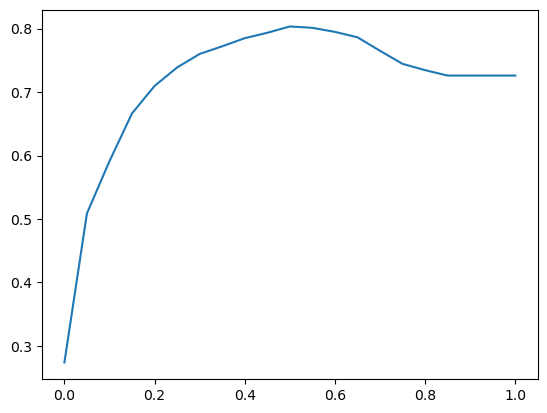

In [11]:
# uporer chart theke dekhtesi ami 0.5 threshold er jonnei best accuracy paitesi. eta graph e dekhi.

plt.plot(thresholds, scores)

In [12]:
# uporer etogula threshold and scores ber korsi eta scikit-learn diye korar way:

from sklearn.metrics import accuracy_score

# single accuracy
accuracy_score(y_val, y_pred >= 0.5)

0.8034066713981547

In [13]:
# now multiple threshold

thresholds = np.linspace (0, 1, 21)

scores = []

for t in thresholds:
    score = accuracy_score(y_val, y_pred >= t)
    scores.append(score)

    print(f'thresholds = {t:.2f} and accuracy = {score: .3f}')
    

thresholds = 0.00 and accuracy =  0.274
thresholds = 0.05 and accuracy =  0.509
thresholds = 0.10 and accuracy =  0.591
thresholds = 0.15 and accuracy =  0.666
thresholds = 0.20 and accuracy =  0.710
thresholds = 0.25 and accuracy =  0.739
thresholds = 0.30 and accuracy =  0.760
thresholds = 0.35 and accuracy =  0.772
thresholds = 0.40 and accuracy =  0.785
thresholds = 0.45 and accuracy =  0.793
thresholds = 0.50 and accuracy =  0.803
thresholds = 0.55 and accuracy =  0.801
thresholds = 0.60 and accuracy =  0.795
thresholds = 0.65 and accuracy =  0.786
thresholds = 0.70 and accuracy =  0.765
thresholds = 0.75 and accuracy =  0.744
thresholds = 0.80 and accuracy =  0.735
thresholds = 0.85 and accuracy =  0.726
thresholds = 0.90 and accuracy =  0.726
thresholds = 0.95 and accuracy =  0.726
thresholds = 1.00 and accuracy =  0.726


### dummy model

In [14]:
'''
1. ami threshold 1 dile model er accurcy hoitese 72%.

2. threshold 1 mane ki? 
    এখানে 1 মানে হলো ১.০০ বা ১০০% সম্ভাবনা। তুমি যখন কোডে লেখো y_pred >= 1.0, তখন তুমি মডেলকে শর্ত দিচ্ছ— "যার Probability একদম কাঁটায় কাঁটায় ১০০% বা তার চেয়ে বেশি, তুমি কেবল তাকেই 'Churn করবে' বলবে। একটু কম হলেও 'না' বলবে।"

    এখন বাস্তব দুনিয়ায় কোনো মেশিন লার্নিং মডেলই কোনো বিষয়ে একদম ১০০% নিশ্চিত হতে পারে না। মডেলের দেওয়া Probability সর্বোচ্চ হয়তো ০.৯৯ (বা ৯৯%) হতে পারে, কিন্তু ১.০০ বা ১০০% হয় না।

    যেহেতু কারোরই Probability ১.০০ এর সমান বা বেশি হয় না, তাই মডেল বাধ্য হয়ে ওই ১৪০৯ জন কাস্টমারের সবার ক্ষেত্রেই উত্তর দেয় "False" বা "না, সে Churn করবে না"।

3. and etai dummy model. mane dataset e shobaikei bolbe je churn korbe na. and actully amader dataset er 73 percent asholei churn kore na. so dummy modle 73 percent accurate.

4. ei dhoroner dataset ke class imbalance bole. and class imbalance er khetre accuracy ke khub ekta believe kora jay na.
'''

pass

In [15]:
len(y_pred)

1409

In [16]:
# dummy model
from collections import Counter
Counter(y_pred >= 1)

Counter({np.False_: 1409})

In [17]:
# amader dummy model bollo dataset er keu ei churn korbe na.

# 0 means not churn and 1 means churn

y_val.mean() # so matro 27 percent churn korse according to dummy model. 

np.float64(0.2739531582682754)

In [18]:
1 - y_val.mean() # etai dummy model er accuracy. which is 72 percent.

np.float64(0.7260468417317246)

In [19]:
# now question holo. dummy model er accuracy jodi 72 percent hoy then amra eto kosto kore dataset prepare kore code likhe model banaya accuracy pailam 80 percent. lav ki? 

# ejonnei ekhon matric gula use kobo nicher module e.

# 4.3 - confusion table

In [20]:
# actual positive and negative from validation dataset
from sklearn.metrics import confusion_matrix


actual_positive = (y_val ==1) # churn
actual_negative = (y_val == 0) # no churn

# preditcted positive and negative from model
t = 0.5
predicted_positive = (y_pred >= t)
predicted_negative = (y_pred <t)

# tp, fp, tn, fn
tp = (predicted_positive & actual_positive).sum()
tn = (predicted_negative & actual_negative).sum()

fp = (predicted_positive & actual_negative).sum()
fn = (predicted_negative & actual_positive).sum()


# now creating confusion matrix
confusion_matrix = np.array([
    [tn, fp],
    [fn, tp]
])

confusion_matrix

array([[922, 101],
       [176, 210]])

In [21]:
# confusion matrix ready korsi but percentage e dekhbo. 
tp+tn+fp+fn

np.int64(1409)

In [22]:
len(y_val)

1409

In [23]:
# mane confusion matrix er sum hobe y_val er soman. tai percentage e ber korbo

(confusion_matrix / confusion_matrix.sum()).round(2)

array([[0.65, 0.07],
       [0.12, 0.15]])

# 4.4 - precision and recall

In [24]:
'''
precision: model jei koytare churn bolse tar moddhe actually churn koyta. 
    tp -> model jader churn bolse and actually churn korse.
    tp + fp -> model total jotojon ke churn bolse (righ or rong)

    precision = tp / (tp + fp)

recall: ashol churn er moddhe dataset koyta churn predict korte parlo
    tp -> model jader churn bolse and asholei churn korse.
    tp + fn -> full dataset e actually jotojon churn korse 

    recall = tp / (tp + fn)
     
'''

'\nprecision: model jei koytare churn bolse tar moddhe actually churn koyta. \n    tp -> model jader churn bolse and actually churn korse.\n    tp + fp -> model total jotojon ke churn bolse (righ or rong)\n\n    precision = tp / (tp + fp)\n\nrecall: ashol churn er moddhe dataset koyta churn predict korte parlo\n    tp -> model jader churn bolse and asholei churn korse.\n    tp + fn -> full dataset e actually jotojon churn korse \n\n    recall = tp / (tp + fn)\n\n'

In [25]:
pricision = tp / (tp + fp)
pricision

# precision 67 percent means model 100 jonke jodi bole churn korse then 67 jon actually churn korse. 

np.float64(0.6752411575562701)

In [26]:
recall = tp / (fp + fn)
recall

# recall 75 percent means jodi 100 jon churn kore model 75 jon kei dhorte parbe.

np.float64(0.7581227436823105)

# 4.5 - roc curve

### step 1: tpr and fpr


**১. Threshold (থ্রেশহোল্ড) এর সমস্যা এবং ROC Curve-এর ধারণা**

আগের লেসনগুলোতে আমরা যখন Precision বা Recall বের করেছি, তখন আমরা মডেলকে জাজ করেছি একটি নির্দিষ্ট **Threshold** বা সীমানার ওপর ভিত্তি করে।

Threshold বিষয়টা কী? ধরো, তোমার মডেল প্রতিটি ইমেইলকে স্প্যাম হওয়ার একটি Probability (সম্ভাবনা) দেয়, যেমন ০.১, ০.৪, ০.৭ ইত্যাদি। সাধারণত আমরা ধরে নিই, Threshold = 0.5 বা ৫০%। অর্থাৎ, মডেল যদি বলে ইমেইলটি স্প্যাম হওয়ার চান্স ৫০% বা তার বেশি, তবেই আমরা তাকে Spam (Positive) বলি। আর ৫০%-এর কম হলে Not Spam (Negative) বলি।

কিন্তু সমস্যা হলো, সব সময় Threshold 0.5 রাখাটা কি ঠিক?

* যদি আমরা খুব কড়াকড়ি করতে চাই, তবে Threshold বাড়িয়ে 0.8 বা ৮০% করে দিতে পারি (খুব সিওর না হলে স্প্যাম বলব না)।
* আবার যদি চাই কোনো স্প্যাম যেন না গলে যায়, তবে Threshold কমিয়ে 0.3 বা ৩০% করে দিতে পারি।

**ROC Curve কেন দরকার?**
আমরা যখন Precision বা Recall মাপি, তখন যেকোনো *একটি নির্দিষ্ট Threshold* (যেমন 0.5)-এ মডেল কেমন করছে শুধু তা দেখতে পাই। কিন্তু একটি মডেল ওভারঅল (Overall) সব ধরনের Threshold-এ কেমন পারফর্ম করে, সেটা একবারে দেখার জন্য যে গ্রাফ বা কার্ভ ব্যবহার করা হয়, তাকেই বলে **ROC Curve**।

**ROC-এর ইতিহাস (দ্বিতীয় বিশ্বযুদ্ধ):**
ROC-এর পূর্ণরূপ হলো **Receiver Operating Characteristic**। এই নামটা মেশিন লার্নিং থেকে আসেনি, এসেছে দ্বিতীয় বিশ্বযুদ্ধের সময় থেকে। তখন রাডারে (Radio Detectors) সিগন্যাল দেখে বুঝতে হতো আকাশে যেটা উড়ছে, সেটা কি শত্রুপক্ষের বিমান (Target/Positive) নাকি নিছকই এক ঝাঁক পাখি (Noise/Negative)। রাডারের সেনসিটিভিটি (Threshold) কমালে-বাড়ালে এটি কতটা নিখুঁতভাবে শত্রুর বিমান ধরতে পারে, তা মাপার জন্যই এই ROC Curve প্রথম তৈরি করা হয়েছিল।

---

ROC Curve তৈরি করতে আমাদের Confusion Matrix-এর সবগুলো মান দরকার হয় না, মূলত দুটি মান বা রেট (Rate) দরকার হয়। একটি হলো **TPR**, আরেকটি হলো **FPR**। চলো এগুলো খুব সহজে বুঝি।

**১. TPR বা True Positive Rate (আসল টার্গেট ধরার হার):**
মজার ব্যাপার হলো, TPR আসলে নতুন কিছু না। আগের লেসনে আমরা যে **Recall** শিখেছি, সেটিকেই এখানে TPR বলা হচ্ছে।

* **সহজ বাংলায়:** বাস্তবে যারা আসল টার্গেট (Positive), তাদের মধ্যে কত পার্সেন্টকে মডেল সঠিকভাবে ধরতে পেরেছে।
* **সূত্র:** $TPR = \frac{TP}{TP + FN}$ (টোটাল আসল পজিটিভের মধ্যে কয়টাকে মডেল পজিটিভ বলেছে)।
* **দারোয়ান উদাহরণ:** তোমার এলাকায় আজ ১০ জন আসল চোর এসেছিল। দারোয়ান তাদের মধ্যে ৮ জনকে ধরতে পেরেছে। তাহলে এখানে TPR বা Recall হলো ৮/১০ = ৮০% বা ০.৮।
* **আমাদের লক্ষ্য:** আমরা সবসময় চাইব মডেলের **TPR যেন সর্বোচ্চ (১ বা ১০০%) হয়**, অর্থাৎ একটা আসল চোরও যেন পালাতে না পারে।

**২. FPR বা False Positive Rate (ফলস অ্যালার্মের হার):**
এটি আমাদের একটু নতুন করে বুঝতে হবে। এটি হলো মডেলের ভুলের হার।

* **সহজ বাংলায়:** বাস্তবে যারা সাধারণ মানুষ বা নির্দোষ (Negative), তাদের মধ্যে কত পার্সেন্টকে মডেল ভুল করে টার্গেট বা চোর (Positive) বানিয়ে ফেলেছে। অর্থাৎ, এটি হলো False Alarm দেওয়ার হার।
* **সূত্র:** $FPR = \frac{FP}{FP + TN}$ (টোটাল সাধারণ মানুষের মধ্যে কয়জনকে মডেল ভুল করে ধরেছে)।
* **দারোয়ান উদাহরণ:** ধরো, সারাদিনে তোমার এলাকায় ১০০ জন সাধারণ নির্দোষ মানুষ (Negative) ঢুকেছে। কিন্তু দারোয়ান সন্দেহ করে তাদের মধ্যে ১০ জনকে ভুল করে চোর ভেবে ধরে ফেলেছে (FP)। তাহলে এখানে FPR হলো ১০/১০০ = ১০% বা ০.১।
* **আমাদের লক্ষ্য:** আমরা সবসময় চাইব মডেলের **FPR যেন সর্বনিম্ন (০ বা ০%) হয়**, অর্থাৎ একজন ভালো মানুষও যেন হয়রানির শিকার না হয়।

**সারসংক্ষেপ:**

* **TPR:** আসল চোরদের মধ্যে কতজনকে ধরতে পারলাম? (এটা বাড়াতে চাই)
* **FPR:** ভালো মানুষদের মধ্যে কতজনকে ভুল করে হয়রানি করলাম? (এটা কমাতে চাই)


In [27]:
tpr = tp/(tp + fn)
tpr

np.float64(0.5440414507772021)

In [28]:
fpr = fp/(fp+tn)
fpr

np.float64(0.09872922776148582)

In [29]:
# main kotha roc curve holo onekula vinno vinno threshold er tpr vs fpr graph.
# nicher code gula 4.3 te kora hoise. but oikhane single threshold diye.

scores = []

thresholds = np.linspace(0, 1, 101)

for t in thresholds:
    actual_positive = (y_val == 1)
    actual_negative = (y_val == 0)
    
    predict_positive = (y_pred >= t)
    predict_negative = (y_pred < t)

    tp = (predict_positive & actual_positive).sum()
    tn = (predict_negative & actual_negative).sum()

    fp = (predict_positive & actual_negative).sum()
    fn = (predict_negative & actual_positive).sum()
    
    scores.append((t, tp, fp, fn, tn))

scores

[(np.float64(0.0), np.int64(386), np.int64(1023), np.int64(0), np.int64(0)),
 (np.float64(0.01), np.int64(385), np.int64(913), np.int64(1), np.int64(110)),
 (np.float64(0.02), np.int64(384), np.int64(830), np.int64(2), np.int64(193)),
 (np.float64(0.03), np.int64(383), np.int64(766), np.int64(3), np.int64(257)),
 (np.float64(0.04), np.int64(381), np.int64(715), np.int64(5), np.int64(308)),
 (np.float64(0.05), np.int64(379), np.int64(685), np.int64(7), np.int64(338)),
 (np.float64(0.06), np.int64(377), np.int64(661), np.int64(9), np.int64(362)),
 (np.float64(0.07), np.int64(372), np.int64(641), np.int64(14), np.int64(382)),
 (np.float64(0.08), np.int64(371), np.int64(613), np.int64(15), np.int64(410)),
 (np.float64(0.09), np.int64(369), np.int64(580), np.int64(17), np.int64(443)),
 (np.float64(0.1), np.int64(366), np.int64(556), np.int64(20), np.int64(467)),
 (np.float64(0.11), np.int64(365), np.int64(528), np.int64(21), np.int64(495)),
 (np.float64(0.12), np.int64(365), np.int64(509), 

In [30]:
# uporer scores list akare ase. now dataframe e convert korbo.

columns = ['threshold', 'tp', 'fp', 'fn', 'tn']
df_scores = pd.DataFrame(scores, columns=columns)

df_scores[::10] # 10 ta row por por dekhbo.

,threshold,tp,fp,fn,tn
0,0.0,386,1023,0,0
10,0.1,366,556,20,467
20,0.2,333,356,53,667
30,0.3,284,236,102,787
40,0.4,249,166,137,857
50,0.5,210,101,176,922
60,0.6,150,53,236,970
70,0.7,75,20,311,1003
80,0.8,13,1,373,1022
90,0.9,0,0,386,1023


In [31]:
# upore amra tpr and fpr ber korsi single threshold diye. ekhon multiple threshold diye ber korbo.

df_scores['tpr'] = df_scores.tp / (df_scores.tp + df_scores.fn)
df_scores['fpr'] = df_scores.fp / (df_scores.fp + df_scores.tn)

df_scores[::10]

,threshold,tp,fp,fn,tn,tpr,fpr
0,0.0,386,1023,0,0,1.000000,1.000000
10,0.1,366,556,20,467,0.948187,0.543500
20,0.2,333,356,53,667,0.862694,0.347996
30,0.3,284,236,102,787,0.735751,0.230694
40,0.4,249,166,137,857,0.645078,0.162268
50,0.5,210,101,176,922,0.544041,0.098729
60,0.6,150,53,236,970,0.388601,0.051808
70,0.7,75,20,311,1003,0.194301,0.019550
80,0.8,13,1,373,1022,0.033679,0.000978
90,0.9,0,0,386,1023,0.000000,0.000000


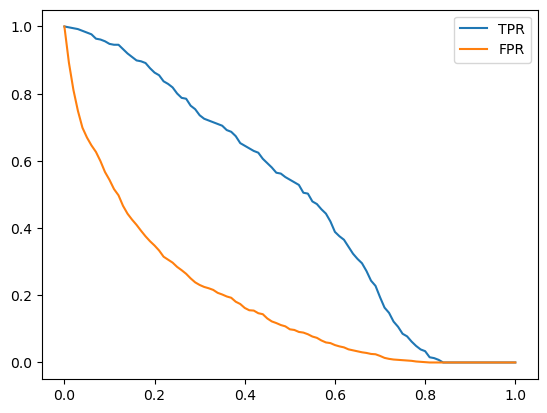

In [32]:
# now ei multiple threshold gular jonne tpr and fpr dekhbo.

plt.plot(df_scores.threshold, df_scores['tpr'], label='TPR')
plt.plot(df_scores.threshold, df_scores['fpr'], label='FPR')
plt.legend()

এই গ্রাফের x-অক্ষে Threshold (0.0 থেকে 1.0) এবং y-অক্ষে Rate (0.0 থেকে 1.0) দেওয়া আছে। এখানে দুটি লাইন দেখা যাচ্ছে:

* **নীল লাইন (TPR - True Positive Rate):** এটি দেখাচ্ছে আমাদের মডেল কতগুলো সঠিক Positive (সঠিক প্রেডিকশন) ধরতে পেরেছে। Threshold যখন একদম 0 (বামে), তখন TPR 1.0 (মানে 100%) থাকে। Threshold যত বাড়ানো হচ্ছে, নীল লাইনটি তত নিচের দিকে নামছে, এর মানে সঠিক Positive ধরার হার আস্তে আস্তে কমে যাচ্ছে।


* **কমলা লাইন (FPR - False Positive Rate):** এটি দেখাচ্ছে মডেল কতগুলো ভুল Positive (ভুল প্রেডিকশন) ধরছে। এটিও 1.0 থেকে শুরু হয়েছে, কিন্তু নীল লাইনের চেয়ে খুব দ্রুত নিচের দিকে নেমে গেছে।



আমাদের মূল লক্ষ্য হলো এমন একটি Threshold খুঁজে বের করা যেখানে TPR অনেক উপরে থাকবে এবং FPR অনেক নিচে থাকবে। তুমি যদি গ্রাফের 0.2 বা 0.3 এর কাছাকাছি Threshold দেখো, তাহলে দেখবে নীল লাইনটি বেশ উপরে (প্রায় 0.8 বা 80%) থাকলেও কমলা লাইনটি অনেকটা নিচে নেমে গেছে (প্রায় 0.3 বা 30%)। এই curve-টি মূলত আমাদেরকে একটি পারফেক্ট Threshold বেছে নিতে সাহায্য করে, যাতে মডেলের ভুল কম হয় এবং সঠিক প্রেডিকশন বেশি হয়।

### step 2: random model

আমাদের বানানো মডেলটা আসলে কতটা ভালো বা খারাপ কাজ করছে, তা বুঝতে হলে আমাদের পয়েন্ট অফ রেফারেন্স (Point of Reference) বা তুলনার জায়গা দরকার। এজন্য আমরা দুটি কাল্পনিক মডেলের কথা চিন্তা করব— একটি একদম বাজে মডেল(random model) এবং আরেকটি একদম পারফেক্ট মডেল(ideal model)।

**১. The Random Model (র‍্যান্ডম বা হাবিজাবি মডেল):**
ধরো, তোমার দারোয়ান কোনো কিছু যাচাই না করে চোখ বন্ধ করে কয়েন টস (Coin flip) করে সিদ্ধান্ত নিচ্ছে কে চোর আর কে ভালো মানুষ। হেড পড়লে বলছে চোর, টেল পড়লে বলছে সাধারণ মানুষ।

* **ফলাফল কী হবে?** যেহেতু তার কোনো লজিক নেই, তাই সে যত পার্সেন্ট আসল চোরকে ধরবে (TPR), ঠিক তত পার্সেন্ট ভালো মানুষকেও ভুল করে ধরবে (FPR)। সে চোর এবং সাধারণ মানুষের মধ্যে কোনো পার্থক্য করতে পারে না।
* **গ্রাফে এটি কেমন দেখায়?** গ্রাফে এটি একদম নিচের বাম কোণ (0,0) থেকে উপরের ডান কোণ (1,1) পর্যন্ত একটি সোজা কোণাকুণি রেখা (Diagonal line) তৈরি করে। এটি হলো আমাদের বেইজলাইন। আমাদের আসল মডেলকে অবশ্যই এই রেখার চেয়ে ভালো হতে হবে, নাহলে বুঝতে হবে মডেলটা কয়েন টস করার মতোই ইউজলেস!

* যেহেতু এটি পুরোটাই র‍্যান্ডম, তাই এর Accuracy হয় প্রায় ৫০%। মজার ব্যাপার হলো, এই মডেলের জন্য TPR এবং FPR-এর মান সবসময় প্রায় সমান থাকে। যেমন: Threshold যদি 0.6 সেট করা হয়, তবে TPR হবে 0.4 এবং FPR-ও হবে 0.4।

* ধরো, তোমার দারোয়ান কোনো কিছু যাচাই না করে চোখ বন্ধ করে কয়েন টস (Coin flip) করে সিদ্ধান্ত নিচ্ছে কে চোর আর কে ভালো মানুষ। হেড পড়লে বলছে চোর, টেল পড়লে বলছে সাধারণ মানুষ।

    ফলাফল কী হবে? যেহেতু তার কোনো লজিক নেই, তাই সে যত পার্সেন্ট আসল চোরকে ধরবে (TPR), ঠিক তত পার্সেন্ট ভালো মানুষকেও ভুল করে ধরবে (FPR)। সে চোর এবং সাধারণ মানুষের মধ্যে কোনো পার্থক্য করতে পারে না।

In [33]:
# random model

np.random.seed(1)
y_random_pred = np.random.uniform(0, 1, size=len(y_val)) # etai shei random model. len(y_val) diye ami validation dataset e jotogula customer ase shobar prediction ber kortesi. prediction ta ber kortesi ekta random number generate kore. random library ta 0 to 1 er moddhe jekono number generate korbe. uniform mane protita digit ashar probability same. but ekhane ekta catch ase. random dile 0 to 1 er moddhe jekono number ashte pare. but onek number hoile like 1k oigular mean 0.5 or er kachakachi ashe. so ekahnew tai ashbe.

y_random_pred

array([4.17022005e-01, 7.20324493e-01, 1.14374817e-04, ...,
       7.73916250e-01, 3.34276405e-01, 8.89982208e-02], shape=(1409,))

In [34]:
accuracy_score_rand = ((y_random_pred >= 0.5) == y_val).mean()

accuracy_score_rand

np.float64(0.5017743080198722)

In [35]:
# ekhon uporer code gula abar repeat korbo. ekta function banabo. oi function y_val and y_pred nibe then multiple threshold er jonne tp, tn, fp,fn,  tpr, fpr er ekta dataframe return korbe. df_scores tai hoilo oi dataframe.

def tpr_fpr_dataframe(y_val, y_pred):
    scores = []

    thresholds = np.linspace(0, 1, 101)

    for t in thresholds:
        actual_positive = (y_val == 1)
        actual_negative = (y_val == 0)

        predict_positive = (y_pred >= t)
        predict_negative = (y_pred < t)

        tp = (predict_positive & actual_positive).sum()
        tn = (predict_negative & actual_negative).sum()

        fp = (predict_positive & actual_negative).sum()
        fn = (predict_negative & actual_positive).sum()

        scores.append((t, tp, fp, fn, tn))

    columns = ['threshold', 'tp', 'fp', 'fn', 'tn']
    df_scores = pd.DataFrame(scores, columns=columns)

    df_scores['tpr'] = df_scores.tp / (df_scores.tp + df_scores.fn)
    df_scores['fpr'] = df_scores.fp / (df_scores.fp + df_scores.tn)
    
    return df_scores

In [36]:
df_rand = tpr_fpr_dataframe(y_val, y_random_pred)

df_rand[::10]

,threshold,tp,fp,fn,tn,tpr,fpr
0,0.0,386,1023,0,0,1.000000,1.000000
10,0.1,347,923,39,100,0.898964,0.902248
20,0.2,307,822,79,201,0.795337,0.803519
30,0.3,276,724,110,299,0.715026,0.707722
40,0.4,237,624,149,399,0.613990,0.609971
50,0.5,202,518,184,505,0.523316,0.506354
60,0.6,161,409,225,614,0.417098,0.399804
70,0.7,121,302,265,721,0.313472,0.295210
80,0.8,78,206,308,817,0.202073,0.201369
90,0.9,40,101,346,922,0.103627,0.098729


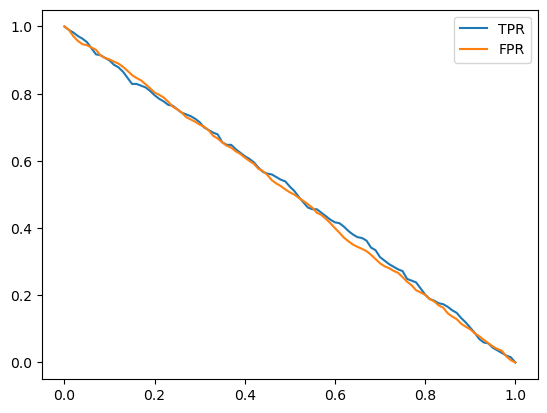

In [37]:
# now graph e plot korbo. uporer code tai.
plt.plot(df_rand.threshold, df_rand['tpr'], label='TPR')
plt.plot(df_rand.threshold, df_rand['fpr'], label='FPR')
plt.legend()

**গ্রাফের তাৎপর্য:**
গ্রাফের মানে হলো, তুমি Threshold যাই পরিবর্তন করো না কেন, মডেলটির সঠিক পজিটিভ (TPR) এবং ভুল পজিটিভ (FPR) ধরার হার সব সময় সমান থাকে। মডেলটি যদি কোনো থ্রেশহোল্ডে ৪০% সঠিক প্রেডিকশন দেয়, তবে সে ৪০% ভুল প্রেডিকশনও দেয়। যেহেতু এখানে সঠিক ও ভুলের অনুপাত সমান, তাই বোঝা যায় মডেলটি ডেটা থেকে কিছুই শিখতে পারেনি এবং এটি কেবল কয়েন টস করার মতো দৈবচয়নে (randomly) ফলাফল দিচ্ছে।

### step 3: ideal model

**কনসেপ্ট নোট: ROC কার্ভ অ্যানালাইসিসে আইডিয়াল মডেল (Ideal Model)**

**সারসংক্ষেপ (Overview)**
"আইডিয়াল মডেল" হলো বাইনারি ক্লাসিফিকেশনের এমন একটি তাত্ত্বিক (theoretical) বেঞ্চমার্ক, যা ১০০% সঠিক প্রেডিকশন দেয়। এটি নেগেটিভ (0) এবং পজিটিভ (1) ক্লাসকে নিখুঁতভাবে আলাদা করে। অর্থাৎ, এটি আসল নেগেটিভ ডেটাগুলোকে সবচেয়ে কম probability বা সম্ভাবনা স্কোর দেয় এবং আসল পজিটিভ ডেটাগুলোকে সবচেয়ে বেশি probability স্কোর দেয়।

**মূল ধারণা এবং ইমপ্লিমেন্টেশন (Key Concept & Implementation)**
পাইথনে একটি আইডিয়াল মডেল মূলত দুটি ধাপে তৈরি করা হয়:

**১. টার্গেট সাজানো (Target Sorting - `y_ideal`)**
```python
y_ideal = np.repeat([0, 1], [num_neg, num_pos])
```
* `np.repeat` ফাংশনটি ব্যবহার করে এমন একটি অ্যারে তৈরি করা হয় যেখানে প্রথমে সবগুলো নেগেটিভ (0) ডেটা থাকে এবং তারপর সবগুলো পজিটিভ (1) ডেটা থাকে।
* **উদাহরণ (৬টি নেগেটিভ, ৪টি পজিটিভ):** `[0, 0, 0, 0, 0, 0, 1, 1, 1, 1]`

**২. প্রবাবিলিটি অ্যাসাইনমেন্ট (Probability Assignment - `y_ideal_pred`)**
```python
y_ideal_pred = np.linspace(0, 1, len(y_ideal))
```
* `np.linspace` ফাংশনটি 0.0 থেকে 1.0 এর মধ্যে সমান দূরত্বের একটি সিকোয়েন্স বা সিরিজ তৈরি করে। 
* সবচেয়ে গুরুত্বপূর্ণ বিষয় হলো, এটি **কোনো র‍্যান্ডম বা এলোমেলো নম্বর তৈরি করে না**। এটি ক্রমান্বয়ে ছোট থেকে বড় হওয়া একটি সিরিজ তৈরি করে।
* **উদাহরণ (১০টি নম্বর):** `[0.00, 0.11, 0.22, 0.33, 0.44, 0.55, 0.66, 0.77, 0.88, 1.00]`

**এটি কীভাবে কাজ করে (ট্রেস টেবিল লজিক)**
যেহেতু আসল টার্গেটগুলো (`y_ideal`) ক্রমানুসারে সাজানো (প্রথমে সব 0, তারপর সব 1) এবং মডেলের প্রেডিক্টেড স্কোরগুলো (`y_ideal_pred`) ক্রমান্বয়ে ছোট থেকে বড় হচ্ছে, তাই স্বাভাবিকভাবেই সবচেয়ে কম স্কোরগুলো 0-এর সাথে এবং সবচেয়ে বেশি স্কোরগুলো 1-এর সাথে মিলে যায়।

**ট্রেস টেবিল উদাহরণ (১০ জন কাস্টমার)**

| কাস্টমার সিরিয়াল | `y_ideal` (আসল ডেটা) | `y_ideal_pred` (মডেলের প্রেডিক্টেড স্কোর) |
| :--- | :--- | :--- |
| ১ | **0** | **0.00** |
| ২ | **0** | **0.11** |
| ৩ | **0** | **0.22** |
| ৪ | **0** | **0.33** |
| ৫ | **0** | **0.44** |
| ৬ | **0** | **0.55** |
| ৭ | **1** | **0.66** |
| ৮ | **1** | **0.77** |
| ৯ | **1** | **0.88** |
| ১০ | **1** | **1.00** |

**পারফেক্ট থ্রেশহোল্ড (Threshold) বের করা**
উপরের টেবিলটি খেয়াল করলে দেখবে, আমরা যদি থ্রেশহোল্ড হিসেবে **0.60** সেট করি, তাহলে:
* যে কাস্টমারদের স্কোর **0.60 এর কম**, মডেল তাদেরকে সঠিকভাবে **0 (Negative)** হিসেবে চিহ্নিত করবে।
* যে কাস্টমারদের স্কোর **0.60 বা তার বেশি**, মডেল তাদেরকে সঠিকভাবে **1 (Positive)** হিসেবে চিহ্নিত করবে।
* এর ফলে মডেলটি ক্লাসগুলোকে নিখুঁতভাবে আলাদা করতে পারে (**TPR = 1.0, FPR = 0.0**), যা ROC কার্ভের গ্রাফে "North Star" বা একদম উপরের বাম দিকের কোণাকে নির্দেশ করে।

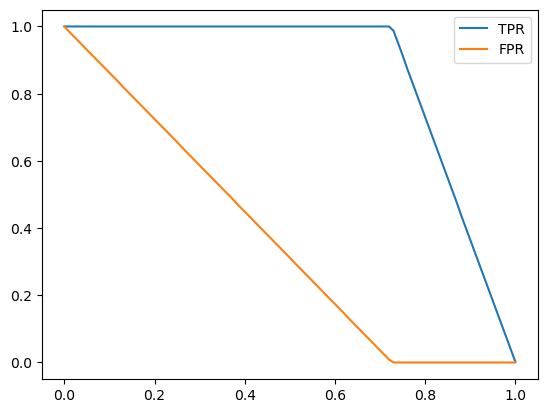

In [38]:
# validation dataset e kotogula positive(churn korse) and negative(churn kore ni) oita ber kori.
num_neg = (y_val == 0).sum() 
num_pos = (y_val == 1).sum()

# প্রথমে সব 0 এবং পরে সব 1 সাজিয়ে একটি আইডিয়াল টার্গেট অ্যারে তৈরি
y_ideal = np.repeat([0, 1], [num_neg, num_pos])
# 0 থেকে 1 পর্যন্ত ক্রমান্বয়ে probability তৈরি করা, যাতে 0 গুলো কম এবং 1 গুলো বেশি স্কোর পায়
y_ideal_pred = np.linspace(0, 1, len(y_ideal))
df_ideal = tpr_fpr_dataframe(y_ideal, y_ideal_pred)

plt.plot(df_ideal.threshold, df_ideal['tpr'], label='TPR')
plt.plot(df_ideal.threshold, df_ideal['fpr'], label='FPR')
plt.legend()

### step 4: putting all the graph together for analysis

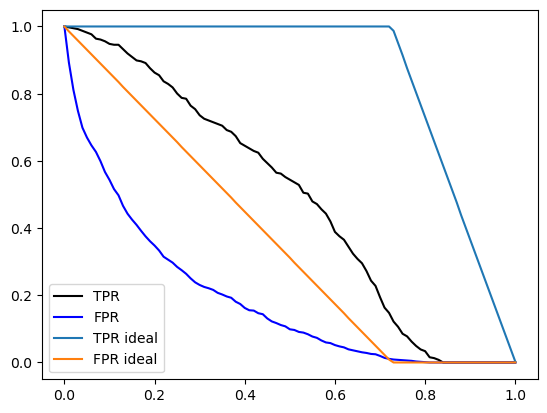

In [39]:
# amar model
plt.plot(df_scores.threshold, df_scores['tpr'], label='TPR', color='black')
plt.plot(df_scores.threshold, df_scores['fpr'], label='FPR', color='blue')

# ideal model
plt.plot(df_ideal.threshold, df_ideal['tpr'], label='TPR ideal')
plt.plot(df_ideal.threshold, df_ideal['fpr'], label='FPR ideal')

# random model
# plt.plot(df_rand.threshold, df_rand['tpr'], label='TPR random', color='grey')
# plt.plot(df_rand.threshold, df_rand['fpr'], label='FPR random', color='grey')

plt.legend()

এই গ্রাফটি মূলত আমাদের **Actual Model** এবং একটি **Ideal (নিখুঁত) Model**-এর মাঝে তুলনা (comparison) দেখাচ্ছে।

**গ্রাফের লাইনগুলোর অর্থ:**

* **TPR ideal (হালকা নীল লাইন) ও FPR ideal (কমলা লাইন):** এই দুটি লাইন Ideal Model-কে নির্দেশ করে। খেয়াল করলে দেখবে, হালকা নীল লাইনটি (TPR ideal) প্রায় 0.72 থ্রেশহোল্ড (threshold) পর্যন্ত একদম 1.0 (100%)-এ সোজা গিয়েছে। ঠিক একই সময়ে কমলা লাইনটি (FPR ideal) নেমে 0 (0%)-তে চলে এসেছে। এর মানে 0.72 থ্রেশহোল্ডে Ideal Model-টি একদম পারফেক্ট (কোনো ভুল নেই)।


* **TPR (কালো লাইন) ও FPR (গাঢ় নীল লাইন):** এই দুটি লাইন আমাদের Actual Model-এর অবস্থা দেখাচ্ছে। কালো লাইনটি (আমাদের TPR) Ideal TPR-এর চেয়ে অনেকটা নিচে নেমে গেছে এবং থ্রেশহোল্ড বাড়ার সাথে সাথে ক্রমান্বয়ে নিচের দিকে নামছে। গাঢ় নীল লাইনটিও (FPR) আস্তে আস্তে নামছে।



**ফলাফল বা সিদ্ধান্ত:**

* **Ideal Model-এর Perfect Spot:** Ideal Model-এর জন্য 0.72-এর কাছাকাছি থ্রেশহোল্ড হচ্ছে বেস্ট, যেখানে TPR 100% থাকে এবং FPR 0% হয়ে যায়।


* **আমাদের Model-এর অবস্থা:** আমাদের Actual Model (কালো লাইন) Ideal Model (হালকা নীল লাইন) থেকে অনেক দূরে আছে। আমাদের মডেলের TPR থ্রেশহোল্ড বাড়ার সাথে সাথে দ্রুত কমে যাচ্ছে, যেটা Ideal Model-এ হয় না। এটি থেকে বোঝা যায় যে, আমাদের মডেলটি পারফেক্ট থেকে এখনো অনেক পিছিয়ে আছে এবং accuracy বাড়ানোর জন্য আরও ইমপ্রুভ করা প্রয়োজন।
* গ্রাফটি খেয়াল করলে দেখবে, থ্রেশহোল্ড যখন 0.4 থেকে 0.5-এর আশেপাশে থাকে, তখন কালো লাইনটি (TPR) বেশ উপরে এবং গাঢ় নীল লাইনটি (FPR) বেশ নিচে থাকে। আগের উদাহরণের Accuracy হিসাব থেকেও আমরা জেনেছিলাম যে আমাদের মডেলের জন্য 0.5 থ্রেশহোল্ড সবচেয়ে ভালো ফলাফল দেয়। অর্থাৎ, Ideal মডেলের বেস্ট থ্রেশহোল্ড 0.72 হলেও, গ্রাফ থেকে দেখা যায় আমাদের মডেলের জন্য বেস্ট থ্রেশহোল্ড 0.5 এর কাছাকাছি হবে।